# 05 · Anchors from k-means: Faster R-CNN and RetinaNet

Analysis only, no training. Compares **k-means anchors** (YOLOv2, Redmon & Farhadi 2016: cluster the training box shapes with distance
`1 − IoU`) with the anchors we actually trained, for both anchor-based detectors.

Two ways of scoring an anchor set:
1. **Shape fit** (the k-means objective): the best IoU between each box shape and any anchor shape, both centred on the same point.
2. **Grid fit** (what training sees): anchors sit on a grid with each feature map's stride (torchvision places anchor centres at
   multiples of the stride), and each anchor size belongs to one feature map. A box is matched against every anchor at its real position.

| | Faster R-CNN RPN | RetinaNet |
|---|---|---|
| Feature maps (strides) | P2–P6 (4, 8, 16, 32, 64) | P3–P7 (8, 16, 32, 64, 128) |
| Anchors | 1 size × 3 ratios per map → 15 shapes | 3 sizes × 3 ratios per map → 45 shapes |
| Positive anchor | IoU ≥ 0.7 | IoU ≥ 0.5 |

Trained configurations, for reference: Faster R-CNN `baseline` and `small_anchors`; RetinaNet `baseline` and `data_anchors` (P3 base 8 px, which collapsed to mAP 0.095),
plus `data_anchors_s2` (P3 base 16 px: anchors ≥ 2× their stride, not trained yet).

## Setup

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.ops import box_iou

PROC_ROOT = Path("../data_processed")
MIN_SIZE, MAX_SIZE = 720, 1280          # the models' internal resize (same protocol as 02 and 04)
N_KMEANS_BOXES = 30_000                 # boxes sampled for clustering
N_GRID_IMAGES = 200                     # training frames used for the grid fit
SEED = 42
rng = np.random.default_rng(SEED)

## Training boxes at the model's input scale

Anchors live in the resized image the model sees (short side 720, long side ≤ 1280), so every box is rescaled by its frame's resize factor.

In [2]:
coco = json.loads((PROC_ROOT / "train" / "annotations_coco.json").read_text())
scale = {im["id"]: min(MIN_SIZE / min(im["width"], im["height"]), MAX_SIZE / max(im["width"], im["height"]))
         for im in coco["images"]}
img_hw = {im["id"]: (round(im["height"] * scale[im["id"]]), round(im["width"] * scale[im["id"]])) for im in coco["images"]}
boxes_by_img = {}
for a in coco["annotations"]:
    if a["iscrowd"]:
        continue
    s = scale[a["image_id"]]
    x, y, w, h = (v * s for v in a["bbox"])
    boxes_by_img.setdefault(a["image_id"], []).append((x, y, x + w, y + h))
del coco

wh = np.array([(b[2] - b[0], b[3] - b[1]) for bs in boxes_by_img.values() for b in bs])
size = np.sqrt(wh.prod(1))
print(f"{len(wh)} boxes in {len(boxes_by_img)} frames")
print("size sqrt(w*h) percentiles:", {q: round(float(v), 1) for q, v in zip([5, 25, 50, 75, 95, 99], np.percentile(size, [5, 25, 50, 75, 95, 99]))})

137982 boxes in 3049 frames
size sqrt(w*h) percentiles: {5: 13.6, 25: 21.6, 50: 30.5, 75: 43.9, 95: 83.8, 99: 130.1}


## k-means with IoU distance

Standard YOLOv2 procedure: assign each box to the centroid with the highest shape IoU, move each centroid to the **median** width and height
of its boxes (more robust to outliers than the mean), repeat until assignments stop changing. Initialised with k-means++ on `1 − IoU`.

In [3]:
def shape_iou(wh, shapes):
    """IoU between box shapes (N, 2) and anchor shapes (K, 2), all centred at the same point."""
    inter = np.minimum(wh[:, None, 0], shapes[None, :, 0]) * np.minimum(wh[:, None, 1], shapes[None, :, 1])
    return inter / (wh.prod(1)[:, None] + shapes.prod(1)[None, :] - inter)

def kmeans_iou(wh, k, seed=SEED, iters=300):
    r = np.random.default_rng(seed)
    centroids = wh[[r.integers(len(wh))]]
    while len(centroids) < k:                          # k-means++ seeding with distance 1 - IoU
        d = 1 - shape_iou(wh, centroids).max(1)
        centroids = np.vstack([centroids, wh[r.choice(len(wh), p=d**2 / (d**2).sum())]])
    assign = None
    for _ in range(iters):
        new = shape_iou(wh, centroids).argmax(1)
        if assign is not None and (new == assign).all():
            break
        assign = new
        centroids = np.array([np.median(wh[assign == j], axis=0) if (assign == j).any() else centroids[j] for j in range(k)])
    return centroids[np.argsort(centroids.prod(1))]   # sorted small -> large

sample = wh[rng.choice(len(wh), min(N_KMEANS_BOXES, len(wh)), replace=False)]
ks = list(range(1, 16)) + [20, 30, 45]
elbow = {k: shape_iou(sample, kmeans_iou(sample, k)).max(1).mean() for k in ks}
KMEANS_15 = kmeans_iou(sample, 15)    # same number of shapes as Faster R-CNN's 5 sizes x 3 ratios
KMEANS_45 = kmeans_iou(sample, 45)    # same number as RetinaNet's 5 x 3 x 3
print("k-means (k=15) centroids (w x h, px):", [f"{w:.0f}x{h:.0f}" for w, h in KMEANS_15])

k-means (k=15) centroids (w x h, px): ['9x13', '11x24', '17x16', '34x15', '24x23', '17x33', '31x31', '44x24', '24x49', '40x43', '63x32', '46x61', '99x50', '70x83', '139x93']


## Anchor configurations

In [4]:
def tv_shapes(sizes, ratios):
    """torchvision anchor shapes for one feature map: every size x ratio, ratio = h / w, area = size^2."""
    return np.array([(s / math.sqrt(r), s * math.sqrt(r)) for s in sizes for r in ratios])

def octave(base):
    return [round(base * 2 ** (k / 3)) for k in range(3)]

FR_STRIDES, RN_STRIDES = (4, 8, 16, 32, 64), (8, 16, 32, 64, 128)
RATIOS = (0.5, 1.0, 2.0)

def assign_to_levels(shapes, level_bases):
    """Put each free-form shape on the feature map whose default anchor size is closest (in log scale)."""
    lvl = np.abs(np.log(np.sqrt(shapes.prod(1)))[:, None] - np.log(np.array(level_bases))[None, :]).argmin(1)
    return [shapes[lvl == i] for i in range(len(level_bases))]

CONFIGS = {
    # name: (feature-map strides, list of anchor shapes per map, positive IoU threshold)
    "FRCNN default (32–512)":       (FR_STRIDES, [tv_shapes([s], RATIOS) for s in (32, 64, 128, 256, 512)], 0.7),
    "FRCNN small_anchors (16–256)": (FR_STRIDES, [tv_shapes([s], RATIOS) for s in (16, 32, 64, 128, 256)], 0.7),
    "FRCNN k-means (15)":           (FR_STRIDES, assign_to_levels(KMEANS_15, (32, 64, 128, 256, 512)), 0.7),
    # 3 sizes per map (RetinaNet-style octave scales) to close the 2x gaps between neighbouring maps
    "FRCNN 3 scales (base 32)":     (FR_STRIDES, [tv_shapes(octave(b), RATIOS) for b in (32, 64, 128, 256, 512)], 0.7),
    "FRCNN 3 scales (base 16)":     (FR_STRIDES, [tv_shapes(octave(b), RATIOS) for b in (16, 32, 64, 128, 256)], 0.7),
    "RetinaNet default (P3 base 32)":  (RN_STRIDES, [tv_shapes(octave(b), RATIOS) for b in (32, 64, 128, 256, 512)], 0.5),
    "RetinaNet data_anchors (base 8)": (RN_STRIDES, [tv_shapes(octave(b), RATIOS) for b in (8, 16, 32, 64, 128)], 0.5),
    "RetinaNet data_anchors_s2 (base 16)": (RN_STRIDES, [tv_shapes(octave(b), RATIOS) for b in (16, 32, 64, 128, 256)], 0.5),
    "RetinaNet k-means (45)":       (RN_STRIDES, assign_to_levels(KMEANS_45, (32, 64, 128, 256, 512)), 0.5),
}
pd.DataFrame({n: {f"P{i}": len(s) for i, s in enumerate(shapes, start=2 if strides[0] == 4 else 3)}
              for n, (strides, shapes, _) in CONFIGS.items()}).T.fillna(0).astype(int).rename_axis("anchor shapes per map")

,P2,P3,P4,P5,P6,P7
anchor shapes per map,,,,,,
FRCNN default (32–512),3,3,3,3,3,0
FRCNN small_anchors (16–256),3,3,3,3,3,0
FRCNN k-means (15),11,3,1,0,0,0
FRCNN 3 scales (base 32),9,9,9,9,9,0
FRCNN 3 scales (base 16),9,9,9,9,9,0
RetinaNet default (P3 base 32),0,9,9,9,9,9
RetinaNet data_anchors (base 8),0,9,9,9,9,9
RetinaNet data_anchors_s2 (base 16),0,9,9,9,9,9
RetinaNet k-means (45),0,32,9,4,0,0


**Faster R-CNN's scale gaps.** Its default anchors have one size per map, each 2× the previous, while the RPN needs IoU ≥ 0.7. An object halfway
between two anchor sizes cannot reach 0.7 with either, so the RPN falls back on its single best (low-quality) match. The two "3 scales"
configurations put three sizes per map (×2^(1/3) apart, as RetinaNet does) to close those gaps. Training them would need 9 anchors per
location instead of 3, i.e. re-initialising the RPN head's last two conv layers (the rest of the pretrained weights still load).

The table shows the **level problem** directly: free-form k-means centroids mostly land on the finest one or two maps,
leaving the coarse maps (large objects) with few or no anchors. torchvision also requires the same number of anchors on every map,
so k-means anchors could not be trained without a custom anchor generator.

## Shape fit vs grid fit

For `N_GRID_IMAGES` training frames we generate every anchor of each configuration at its real grid position and match it to the ground truth.
Per object we record:
- best IoU with any anchor (shape-only and on the grid),
- whether some anchor reaches the model's **positive threshold** (0.7 RPN / 0.5 RetinaNet),
- how many anchors are positive for it,
- **cells across**: object size / stride of the map its best anchor sits on. Below ~2, the object is predicted from features where it covers about one cell.

In [5]:
def grid_anchors(strides, shapes_per_level, h, w):
    """All anchors (xyxy) and their stride, torchvision-style: centres at multiples of the stride on a 32-padded image."""
    H, W = math.ceil(h / 32) * 32, math.ceil(w / 32) * 32
    out, lvl_stride = [], []
    for s, shapes in zip(strides, shapes_per_level):
        if len(shapes) == 0:
            continue
        ys, xs = np.meshgrid(np.arange(math.ceil(H / s)) * s, np.arange(math.ceil(W / s)) * s, indexing="ij")
        c = np.stack([xs.ravel(), ys.ravel()], 1)
        half = np.asarray(shapes)[None, :, :] / 2
        a = np.concatenate([c[:, None] - half, c[:, None] + half], 2).reshape(-1, 4)
        out.append(a)
        lvl_stride.append(np.full(len(a), s))
    return torch.tensor(np.concatenate(out), dtype=torch.float32), np.concatenate(lvl_stride)

frames = rng.choice(list(boxes_by_img), min(N_GRID_IMAGES, len(boxes_by_img)), replace=False)
rows = []
for name, (strides, shapes, thr) in CONFIGS.items():
    all_shapes = np.concatenate([s for s in shapes if len(s)])
    for img_id in frames:
        gt = torch.tensor(boxes_by_img[img_id], dtype=torch.float32)
        anchors, a_stride = grid_anchors(strides, shapes, *img_hw[img_id])
        iou = box_iou(gt, anchors)
        best_iou, best_idx = iou.max(1)
        g_wh = (gt[:, 2:] - gt[:, :2]).numpy()
        g_size = np.sqrt(g_wh.prod(1))
        rows.append(pd.DataFrame({
            "config": name, "size": np.where(g_wh.prod(1) < 32**2, "small", "medium+"),
            "shape IoU": shape_iou(g_wh, all_shapes).max(1), "grid IoU": best_iou.numpy(),
            "has positive": (best_iou >= thr).numpy(), "positives": (iou >= thr).sum(1).numpy(),
            "cells across": g_size / a_stride[best_idx.numpy()]}))
fit = pd.concat(rows, ignore_index=True)

def summarise(df):
    return pd.Series({"shape IoU": df["shape IoU"].mean(), "grid IoU": df["grid IoU"].mean(),
                      "objects with a positive": df["has positive"].mean(),
                      "small objects with a positive": df.loc[df["size"] == "small", "has positive"].mean(),
                      "positives / object": df["positives"].mean(),
                      "best anchor < 2 cells across": (df["cells across"] < 2).mean()})

table = fit.groupby("config", sort=False).apply(summarise)
table.round(3)

,shape IoU,grid IoU,objects with a positive,small objects with a positive,positives / object,best anchor < 2 cells across
config,,,,,,
FRCNN default (32–512),0.599,0.589,0.359,0.255,1.205,0.008
FRCNN small_anchors (16–256),0.694,0.649,0.320,0.304,0.394,0.008
FRCNN k-means (15),0.779,0.747,0.759,0.737,2.586,0.008
FRCNN 3 scales (base 32),0.659,0.647,0.596,0.255,4.073,0.008
FRCNN 3 scales (base 16),0.812,0.754,0.842,0.798,1.839,0.008
RetinaNet default (P3 base 32),0.659,0.617,0.735,0.497,14.155,0.091
RetinaNet data_anchors (base 8),0.828,0.540,0.592,0.605,1.765,0.856
RetinaNet data_anchors_s2 (base 16),0.812,0.661,0.955,0.920,6.447,0.169
RetinaNet k-means (45),0.860,0.722,0.967,0.939,22.855,0.091


## Plots

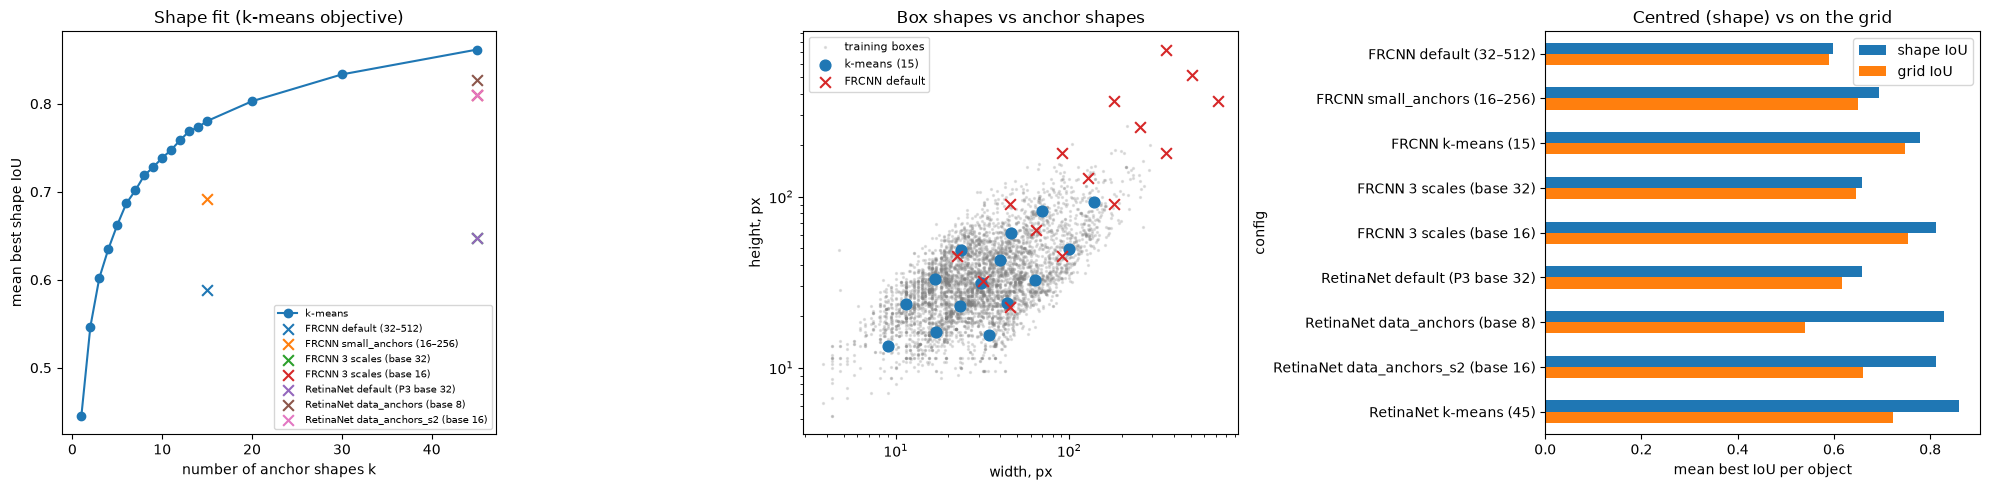

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Elbow: shape fit of k-means vs number of anchors, with the trained configurations as reference points
ax = axes[0]
ax.plot(list(elbow), list(elbow.values()), "o-", color="C0", label="k-means")
for name, (strides, shapes, _) in CONFIGS.items():
    if "k-means" in name:
        continue
    all_shapes = np.concatenate([s for s in shapes if len(s)])
    ax.scatter(len(all_shapes), shape_iou(sample, all_shapes).max(1).mean(), marker="x", s=60, label=name)
ax.set(xlabel="number of anchor shapes k", ylabel="mean best shape IoU", title="Shape fit (k-means objective)")
ax.legend(fontsize=7)

# 2. Box shapes with k-means centroids and default anchors
ax = axes[1]
pts = sample[rng.choice(len(sample), 5000, replace=False)]
ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.2, color="grey", label="training boxes")
ax.scatter(*KMEANS_15.T, s=60, color="C0", label="k-means (15)")
ax.scatter(*np.concatenate(CONFIGS["FRCNN default (32–512)"][1]).T, s=60, marker="x", color="C3", label="FRCNN default")
ax.set(xscale="log", yscale="log", xlabel="width, px", ylabel="height, px", title="Box shapes vs anchor shapes")
ax.legend(fontsize=8)

# 3. Shape fit vs grid fit per configuration
ax = axes[2]
table[["shape IoU", "grid IoU"]].plot.barh(ax=ax)
ax.set(xlabel="mean best IoU per object", title="Centred (shape) vs on the grid")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

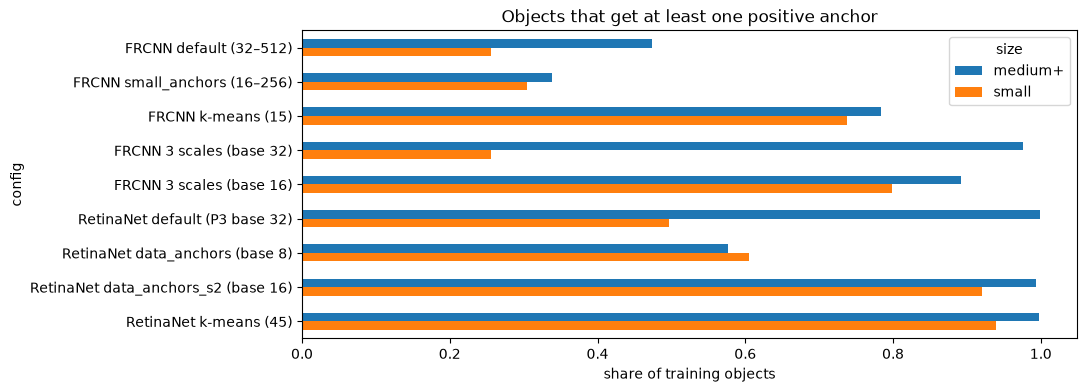

size,medium+,small
config,,
FRCNN default (32–512),0.474,0.255
FRCNN small_anchors (16–256),0.338,0.304
FRCNN k-means (15),0.784,0.737
FRCNN 3 scales (base 32),0.976,0.255
FRCNN 3 scales (base 16),0.892,0.798
RetinaNet default (P3 base 32),0.999,0.497
RetinaNet data_anchors (base 8),0.577,0.605
RetinaNet data_anchors_s2 (base 16),0.994,0.920
RetinaNet k-means (45),0.998,0.939


In [7]:
# Share of objects with a positive anchor, by object size: the quantity training actually depends on
by_size = fit.groupby(["config", "size"], sort=False)["has positive"].mean().unstack()
by_size.plot.barh(figsize=(10, 4), title="Objects that get at least one positive anchor")
plt.xlabel("share of training objects"); plt.gca().invert_yaxis(); plt.show()
by_size.round(3)

**Observations:** _fill in: how much k-means improves the shape fit, how much of that survives on the grid,
which configurations leave small objects without a positive anchor, and how this lines up with the trained results
(e.g. `small_anchors` in 02, `data_anchors` in 04)._